# 📝 MINI PROJECT: TEXT GENERATION BAHASA INDONESIA
## Komparasi Language Model: LSTM vs. GRU (Next-Word Prediction)
**Tugas Lanjutan Pertemuan 11 & 12 — Pemrosesan Bahasa Alami (NLP)**  
**Program Studi:** S1 Teknik Informatika — Universitas Negeri Malang (UM)  
**Dosen Pengampu:** Prof. Ir. Aji Prasetya Wibawa, S.T., M.M.T., Ph.D. & M. Zainal Arifin, S.Si., M.Kom., Ph.D.  
**Mentor Asisten:** Agung Bella Putra Utama & Fadia Irsania Putri  

---

### 👥 Pembagian Peran & Job Desk Tim (5 Anggota)

| No | NIM | Nama Mahasiswa | Peran & Tanggung Jawab Utama |
| :-: | :---: | :--- | :--- |
| **1** | `240535601034` | **ALBI ADWITIYA CHANDRA** | **Pengembang Model 1 (LSTM Language Model):**<br>• Membangun layer arsitektur LSTM (`layers.LSTM(RNN_UNITS)`).<br>• Pelatihan model LSTM dengan Early Stopping & pencatatan durasi training.<br>• Pengujian generasi teks LSTM pada berbagai tingkat temperature (0.5 - 1.2). |
| **2** | `240535610197` | **INDAH HARIYANTI** | **Pengembang Model 2 (GRU Language Model):**<br>• Membangun layer arsitektur GRU (`layers.GRU(RNN_UNITS)`).<br>• Pelatihan model GRU dengan Early Stopping & pencatatan durasi training.<br>• Analisis efisiensi komputasi & parameter GRU dibandingkan LSTM. |
| **3** | `240535604624` | **CHRISTIAN LIONEL DAUN DARMA** | **Data Preparation, Evaluator & Kesimpulan:**<br>• Pemuatan & kurasi dataset `indonesian-nlp/wikipedia-id` dari HuggingFace.<br>• Evaluasi kuantitatif: Training/Validation Loss, Perplexity, dan Next-Word Accuracy.<br>• Evaluasi kualitatif 10 prompt (relevansi, koherensi, repetisi) & penulisan kesimpulan. |
| **4** | `240535600363` | **ASYAM SAKHI MAULANA** | **Mini Project Text Summarization:** Model 1 (TF-IDF Sentence Ranking). |
| **5** | `240535607403` | **AGUSTINUS MARIA AGUNG HERIYANTO** | **Mini Project Text Summarization:** Model 2 (TextRank Algorithm). |

---

### 🎯 Tujuan & Aspek Komparasi Sesuai Slide 21 PDF
Masing-masing kelompok wajib membandingkan kedua model generasi teks dari sisi:
1. **Training Loss dan Validation Loss**
2. **Perplexity** (Tingkat ketidakpastian model dalam menebak kata berikutnya)
3. **Next-Word Accuracy** (Akurasi prediksi kata berikutnya pada test set)
4. **Waktu Training** (Efisiensi komputasi detik per epoch)
5. **Kualitas Teks Hasil Generasi** (Gramatikal, keluwesan bahasa Indonesia)
6. **Koherensi dan Relevansi terhadap Prompt Awal**
7. **Tingkat Repetisi Kata** (Kecenderungan looping / pengulangan frasa)
8. **Pengaruh Hyperparameter Temperature** (0.5, 0.8, 1.0, 1.2)
9. **Contoh Output Terbaik dan Terburuk**
10. **Analisis Error & Jawaban Pertanyaan:** *Apakah model dengan perplexity lebih rendah selalu menghasilkan teks yang lebih natural?*

*Catatan: Sangat disarankan mengaktifkan akselerator GPU di Google Colab: `Runtime > Change runtime type > T4 GPU`.*


## 1. Setup & Konfigurasi

In [ ]:
# Instalasi datasets Hugging Face jika belum terpasang
!pip install --quiet datasets

from datasets import load_dataset
import os
import json
import time
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import layers, models

from IPython.display import display

# Seed eksperimen
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Hyperparameter sesuai modul praktikum
EMB_DIM = 64
RNN_UNITS = 96
EPOCHS = 8
BATCH_SIZE = 64
PATIENCE = 2

DATASET_PATH = "dataset_text_generation_indonesia.csv"

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)
print("GPU tersedia:", tf.config.list_physical_devices("GPU"))


TensorFlow version: 2.21.0
NumPy version: 2.4.6
GPU tersedia: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:

# Memuat dataset Hugging Face sesuai sumber data yang digunakan
ds = load_dataset("indonesian-nlp/wikipedia-id")

print(ds)
print("Kolom dataset:", ds["train"].column_names)
print("Jumlah data train:", len(ds["train"]))
print("Jumlah data test :", len(ds["test"]))

# Mengambil sampel acak dari split train agar eksperimen dapat direproduksi.
# Ambil pool lebih besar agar setelah pembersihan tetap tersedia 700 artikel.
SAMPLE_SIZE = 700
SAMPLE_POOL_SIZE = min(5000, len(ds["train"]))

sample_pool = ds["train"].shuffle(seed=SEED).select(range(SAMPLE_POOL_SIZE))
df = sample_pool.to_pandas()

# Pastikan kolom yang diperlukan tersedia
required_columns = {"docid", "title", "text"}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"Kolom dataset tidak ditemukan: {missing_columns}")

# Bersihkan nilai text kosong, spasi berlebih di tepi, dan duplikasi artikel.
# Tidak melakukan normalisasi agresif agar isi teks sumber tetap terjaga.
df["text"] = df["text"].fillna("").astype(str).str.strip()
df = df[df["text"] != ""].copy()
df = df.drop_duplicates(subset=["text"]).reset_index(drop=True)

# Hindari artikel yang terlalu pendek untuk tugas next-word prediction.
df["word_count_original"] = df["text"].str.split().str.len()
df = df[df["word_count_original"] >= 20].copy()

if len(df) < SAMPLE_SIZE:
    raise ValueError(
        f"Setelah pemeriksaan data hanya tersedia {len(df)} artikel valid. "
        "Naikkan SAMPLE_POOL_SIZE agar memperoleh minimal 700 artikel."
    )

# Tetapkan tepat 700 artikel untuk eksperimen ini.
df = df.head(SAMPLE_SIZE).reset_index(drop=True)

print("Jumlah artikel terpilih:", len(df))
print("Kolom:", df.columns.tolist())
display(df[["docid", "title", "text", "word_count_original"]].head())

assert len(df) == SAMPLE_SIZE
assert df["text"].notna().all()
assert (df["text"].str.strip() != "").all()


DatasetDict({
    train: Dataset({
        features: ['docid', 'title', 'text'],
        num_rows: 1301683
    })
    test: Dataset({
        features: ['docid', 'title', 'text'],
        num_rows: 144632
    })
})
Kolom dataset: ['docid', 'title', 'text']
Jumlah data train: 1301683
Jumlah data test : 144632
Jumlah artikel terpilih: 700
Kolom: ['docid', 'title', 'text', 'word_count_original']


,docid,title,text,word_count_original
0,846457#2,V-22 Osprey,"Dua buah mesin Rolls-Royce AE 1107C pada kedua ujung sayap dihubungkan dengan poros penggerak ke kotak roda gigi pusat bersama, sehingga satu buah mesin dapat menggerakkan kedua proprotor jika salah satu mesin mengalami kegagalan. Sebagian besar ...",71
1,1215476#0,(66272) 1999 JW6,"(66272) 1999 JW6 adalah sebuah asteroid. Asteroid ini merupakan bagian dari asteroid Amor, yang terletak dekat dengan bumi. Eksentrisitas orbit asteroid ini tercatat sebesar 0.143, sementara magnitudo mutlaknya adalah 17.1.",30
2,226157#22,Rinto Harahap,"Popularitas Rinto bersama Lolypop mulai terlibas dengan kehadiran Judi Kristianto yang saat itu juga mengibarkan pop manis lewat label JK Records di pertengahan tahun 1980-an. Pemunculan penyanyi Dian Piesesha, Helen Sparingga, Meriam Bellina, An...",132
3,524559#69,Pertanian dan perkebunan di Indonesia,"Selain itu, kelapa banyak terdapat di Aceh, Bengkulu, Jambi, Jawa Barat, Kalimantan Barat, Kalimantan Tengah, Kalimantan Timur, Papua, Riau, Sulawesi Tenggara, Sumatera Selatan, dan DI Yogyakarta.\n19. Kelapa Sawit",29
4,1224627#0,(16816) 1997 UF9,"(16816) 1997 UF9 adalah sebuah asteroid. Asteroid ini merupakan bagian dari asteroid Apollo, yang terletak dekat dengan bumi. Eksentrisitas orbit asteroid ini tercatat sebesar 0.604, sementara magnitudo mutlaknya adalah 16.1.",30


## Pembagian Data (80% train / 10% validation / 10% test)

In [ ]:
n = len(df)
a = int(.8*n)
b = int(.9*n)
train_texts = df.iloc[:a].text.tolist()
val_texts   = df.iloc[a:b].text.tolist()
test_texts  = df.iloc[b:].text.tolist()
print(len(train_texts), len(val_texts), len(test_texts))

560 70 70


##Tokenisasi dan Pembentukan Sequence

In [ ]:
tokenizer = Tokenizer(oov_token='<OOV>')
tokenizer.fit_on_texts(train_texts)          # hanya di-fit pada data train
vocab_size = len(tokenizer.word_index) + 1
index_word = tokenizer.index_word
print("vocab_size:", vocab_size)

def make_seq(texts):
    seq = []
    for text in texts:
        ids = tokenizer.texts_to_sequences([text])[0]
        for i in range(1, len(ids)):
            seq.append(ids[:i+1])            # n-gram bertingkat
    return seq

vocab_size: 4631


##Padding dan Pemisahan X–y

In [ ]:
tr, va, te = make_seq(train_texts), make_seq(val_texts), make_seq(test_texts)
max_len = max(map(len, tr))

def prep(seq):
    p = pad_sequences(seq, maxlen=max_len, padding='pre')
    return p[:, :-1], p[:, -1]

X_train, y_train = prep(tr)
X_val,   y_val   = prep(va)
X_test,  y_test  = prep(te)
print("max_len:", max_len, "| X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test:", X_test.shape)

max_len: 41 | X_train: (15547, 40) | X_val: (1956, 40) | X_test: (1953, 40)


##Membangun Model LSTM dan GRU

In [ ]:
def build_model(kind):
    inp = layers.Input(shape=(max_len-1,))
    x = layers.Embedding(vocab_size, EMB_DIM)(inp)
    if kind == 'LSTM':
        # Model 1 (Albi): Long Short-Term Memory
        x = layers.LSTM(RNN_UNITS)(x)
    elif kind == 'GRU':
        # Model 2 (Indah): Gated Recurrent Unit
        x = layers.GRU(RNN_UNITS)(x)
    else:
        raise ValueError(f"Model {kind} tidak dikenali.")
    out = layers.Dense(vocab_size, activation='softmax')(x)
    m = models.Model(inp, out, name=f"LanguageModel_{kind}")
    m.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
    return m

# Inisialisasi Model 1 (LSTM - Albi)
lstm_model = build_model('LSTM')
lstm_model.summary()

# Inisialisasi Model 2 (GRU - Indah)
gru_model = build_model('GRU')
gru_model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 40)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 40, 64)         │       296,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 96)             │        61,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4631)           │       449,207 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 807,415 (3.08 MB)

 Trainable params: 807,415 (3.08 MB)

 Non-trainable params: 0 (0.00 B)

##Training dengan Early Stopping

### Model 1 — LSTM ✅

In [ ]:
cb = [tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=2, restore_best_weights=True)]

t0 = time.time()
h1 = lstm_model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=cb)
time_lstm = time.time() - t0
print(f"Waktu training LSTM: {time_lstm:.1f} detik")

Epoch 1/8
243/243 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.0291 - loss: 7.3253 - val_accuracy: 0.0353 - val_loss: 6.8777
Epoch 2/8
243/243 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.0444 - loss: 6.5921 - val_accuracy: 0.0711 - val_loss: 6.7871
Epoch 3/8
243/243 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.0770 - loss: 6.2500 - val_accuracy: 0.1273 - val_loss: 6.7520
Epoch 4/8
243/243 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.1221 - loss: 5.9853 - val_accuracy: 0.1708 - val_loss: 6.7204
Epoch 5/8
243/243 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.1589 - loss: 5.7597 - val_accuracy: 0.2060 - val_loss: 6.7078
Epoch 6/8
243/243 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.1894 - loss: 5.5532 - val_accuracy: 0.2423 - val_loss: 6.7183
Epoch 7/8
243/243 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.2130 - loss: 5.3483 - val_accuracy: 0.2618 - val_loss: 6.7152
Waktu training LSTM: 20.9 detik


### Model 2 — GRU 🔲 *(TODO)*
Jalankan semua cell di atas (6.1–6.5) terlebih dahulu, isi cabang GRU di `build_model()`, lalu jalankan cell berikut. **Jangan ubah hyperparameter** agar perbandingan adil.

In [ ]:
# ==============================================================================
# Model 2 — GRU (Penanggung Jawab: Indah Hariyanti - 240535610197)
# ==============================================================================
cb_gru = [tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True)]
t0 = time.time()
h2 = gru_model.fit(X_train, y_train,
                   validation_data=(X_val, y_val),
                   epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=cb_gru)
time_gru = time.time() - t0
print(f"Waktu training GRU: {time_gru:.1f} detik")


### Kurva Training Loss vs Validation Loss

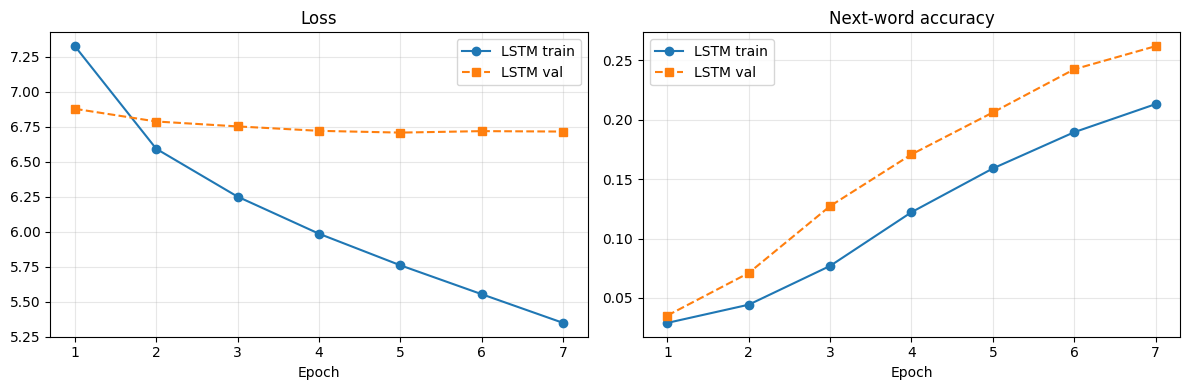

In [ ]:
def plot_history(histories):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for name, h in histories.items():
        ep = range(1, len(h.history['loss'])+1)
        ax[0].plot(ep, h.history['loss'], marker='o', label=f'{name} train')
        ax[0].plot(ep, h.history['val_loss'], marker='s', ls='--', label=f'{name} val')
        ax[1].plot(ep, h.history['accuracy'], marker='o', label=f'{name} train')
        ax[1].plot(ep, h.history['val_accuracy'], marker='s', ls='--', label=f'{name} val')
    ax[0].set_title('Loss'); ax[1].set_title('Next-word accuracy')
    for a_ in ax: a_.set_xlabel('Epoch'); a_.legend(); a_.grid(alpha=.3)
    plt.tight_layout(); plt.show()

histories = {'LSTM': h1}
# histories['GRU'] = h2      # TODO: aktifkan setelah GRU dilatih
plot_history(histories)

##Evaluasi Model (Loss, Perplexity, Accuracy, Waktu Training)

In [ ]:
def eval_lm(m):
    loss, acc = m.evaluate(X_test, y_test, verbose=0)
    return loss, float(np.exp(loss)), acc

a_ = eval_lm(lstm_model)
# b_ = eval_lm(gru_model)    # TODO: aktifkan setelah GRU dilatih

res = pd.DataFrame({
    'Model': ['LSTM'],            # TODO: tambahkan 'GRU'
    'Test Loss': [a_[0]],         # TODO: tambahkan b_[0]
    'Perplexity': [a_[1]],        # TODO: tambahkan b_[1]
    'Next-word Accuracy': [a_[2]],# TODO: tambahkan b_[2]
    'Training Time (s)': [time_lstm]  # TODO: tambahkan time_gru
})
res

,Model,Test Loss,Perplexity,Next-word Accuracy,Training Time (s)
0,LSTM,7.303844,1486.001823,0.132104,20.853691


##Menghasilkan Teks (Temperature Sampling)

In [ ]:
def generate_text(model, seed_text, n_words=20, temperature=.8):
    text = seed_text.strip()
    for _ in range(n_words):
        seq = tokenizer.texts_to_sequences([text])[0]
        seq = pad_sequences([seq], maxlen=max_len-1, padding='pre')
        p = model.predict(seq, verbose=0)[0].astype('float64')
        p[0] = 0
        p = np.log(p + 1e-12) / max(temperature, 1e-6)
        p = np.exp(p - p.max())
        p = p / p.sum()
        nid = np.random.choice(len(p), p=p)
        text += ' ' + index_word.get(nid, '<OOV>')
    return text

def repetition_rate(text):
    """1 - distinct-2 pada kata hasil generasi; 0 = tidak ada pengulangan bigram."""
    w = text.split()
    bg = list(zip(w[:-1], w[1:]))
    return 0.0 if not bg else 1 - len(set(bg)) / len(bg)

###Contoh Pengujian LSTM vs GRU

In [ ]:
np.random.seed(42)
print('LSTM:', generate_text(lstm_model, 'indonesia adalah negara'))
# np.random.seed(42)
# print('GRU :', generate_text(gru_model,  'indonesia adalah negara'))   # TODO

LSTM: indonesia adalah negara spesies desa panjang spesies yang juga yang panjang ini genus juga tanduk animalia juga merupakan kayu ini ordo coleoptera kelas


###Pengaruh Temperature (0.5, 0.8, 1.0, 1.2)

In [ ]:
for temp in [0.5, 0.8, 1.0, 1.2]:
    print('\nTemperature', temp)
    np.random.seed(42)
    print('LSTM:', generate_text(lstm_model, 'kota jakarta merupakan', 18, temp))
    # np.random.seed(42)
    # print('GRU :', generate_text(gru_model, 'kota jakarta merupakan', 18, temp))   # TODO


Temperature 0.5
LSTM: kota jakarta merupakan adalah sebuah sebuah satu di kota dan red nayoan pada dan kekalahan terjadi di sekitar di masa nya

Temperature 0.8
LSTM: kota jakarta merupakan tahun rahadian adalah indonesia yang dalam di mentahqiq simplelinux episode dan kekalahan perpecahan 2000 9 di paling padang

Temperature 1.0
LSTM: kota jakarta merupakan umumnya produsen born corinthians adalah pada di kesembilan menyukai 1907 dan bavaria 605 yang pemain beberapa tanggal raja

Temperature 1.2
LSTM: kota jakarta merupakan kata datang melepaskan segi jerman kota yang tracks satu terbang dengan madra semua bernama kanan dari situs kapoor


In [ ]:
# Tingkat repetisi per temperature (rata-rata 5 sampel) -> bahan analisis
def repetition_by_temp(model, seed='pada tahun', n=5):
    out = {}
    for temp in [0.5, 0.8, 1.0, 1.2]:
        r = []
        for k in range(n):
            np.random.seed(k)
            r.append(repetition_rate(generate_text(model, seed, 30, temp)))
        out[temp] = round(float(np.mean(r)), 3)
    return out

rep = {'LSTM': repetition_by_temp(lstm_model)}
# rep['GRU'] = repetition_by_temp(gru_model)     # TODO
pd.DataFrame(rep).rename_axis('Temperature')

,LSTM
Temperature,
0.5,0.032
0.8,0.065
1.0,0.000
1.2,0.000


## Evaluasi Kualitatif (≥ 10 prompt, skala 1–5)
Gunakan **prompt yang sama** untuk LSTM dan GRU. Aspek: **Koherensi, Relevansi, Repetisi, Grammar, Diversity**.
Cell berikut membuat 10 prompt dan menghasilkan teks (temperature 0.8) untuk dinilai manual.

In [ ]:
EVAL_PROMPTS = [
    'indonesia adalah negara', 'presiden republik indonesia', 'kota jakarta merupakan',
    'pada tahun 1945', 'universitas gadjah mada', 'pulau jawa adalah',
    'bahasa indonesia digunakan', 'sungai ini terletak di', 'pertandingan sepak bola',
    'film ini disutradarai oleh',
]
ASPEK = ['Koherensi', 'Relevansi', 'Repetisi', 'Grammar', 'Diversity']

def collect(models_dict, temp=0.8, n_words=20):
    rows = []
    for name, m in models_dict.items():
        for p in EVAL_PROMPTS:
            np.random.seed(42)
            rows.append({'Model': name, 'Prompt': p, 'Teks': generate_text(m, p, n_words, temp),
                         **{a_: None for a_ in ASPEK}})
    return pd.DataFrame(rows)

eval_models = {'LSTM': lstm_model}
# eval_models['GRU'] = gru_model      # TODO
qual = collect(eval_models)
pd.set_option('display.max_colwidth', 250)
qual     # isi skor 1-5 untuk kelima aspek (edit manual / ekspor ke Sheets)

,Model,Prompt,Teks,Koherensi,Relevansi,Repetisi,Grammar,Diversity
0,LSTM,indonesia adalah negara,indonesia adalah negara spesies desa panjang spesies yang juga yang panjang ini genus juga tanduk animalia juga merupakan kayu ini ordo coleoptera kelas,None,None,None,None,None
1,LSTM,presiden republik indonesia,presiden republik indonesia adalah audit mechanism apt yang dalam di interventional lewat fukuoka yang brie sebagai liga ini di teman memainkan industri ini,None,None,None,None,None
2,LSTM,kota jakarta merupakan,kota jakarta merupakan tahun rahadian adalah indonesia yang dalam di mentahqiq simplelinux episode dan kekalahan perpecahan 2000 9 di paling padang barat ini,None,None,None,None,None
3,LSTM,pada tahun 1945,pada tahun 1945 ia terrorcons barat adalah di kecamatan new dijajal adalah 6 yang bersekolah oleh sm di gol dari gazahar di seluruh,None,None,None,None,None
4,LSTM,universitas gadjah mada,universitas gadjah mada spesies tanduk panjang kumbang yang kayu yang biasanya famili cerambycidae dan familia araneae juga merupakan bagian ini insecta filum insecta,None,None,None,None,None
5,LSTM,pulau jawa adalah,pulau jawa adalah adalah bioskop bahwa komedi adalah ini yang 453 hingga danau dan izin khusus jenis juta yang serta united dari faktor,None,None,None,None,None
6,LSTM,bahasa indonesia digunakan,bahasa indonesia digunakan adalah pembinaan kumbang pada dalam spesies yang biasanya famili cerambycidae dan berpori animalia juga merupakan kayu ini ordo coleoptera kelas,None,None,None,None,None
7,LSTM,sungai ini terletak di,sungai ini terletak di berbeda tengah sebelum sosial yang tahun jalan artis sebagai sayap yang kerajinan dulu dan bidang pasukan bidang bidakademik elemen di,None,None,None,None,None
8,LSTM,pertandingan sepak bola,pertandingan sepak bola satu atronitens adalah biasanya tahun tiongkok amerika milik bersama dengan untuk tni panda yang tidak dia pada bahasa dilengkapi 2008,None,None,None,None,None
9,LSTM,film ini disutradarai oleh,film ini disutradarai oleh budaya forget zhu berhasil rakyat di menjadi ad penerapan banjarmasin dan 40 km² memenangkannya dan agung tidak pantai sd saat dari,None,None,None,None,None


In [ ]:
# Setelah skor diisi, rata-ratakan per model:
# qual[ASPEK] = qual[ASPEK].astype(float)
# qual.groupby('Model')[ASPEK].mean().round(2)